# Practical 3 · Decision trees, step by step (churn + a regression tree)

**Goal:** predict churn with a **decision tree**, see the questions it learns, understand overfitting, and tune it.

Steps 0–7 (load, clean, split, feature types) are **exactly the same as Practical 2**, so they are in one cell below. If anything there is unclear, go back to Practical 2, which explains each one.

## Steps 0–7 · Load, clean, split (same as Practical 2)

In [1]:
import os
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid'); plt.rcParams['figure.figsize'] = (8, 4.5)

# Step 1 - load
url = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/telco-churn.csv'
if not os.path.exists('telco-churn.csv'):
    urlretrieve(url, 'telco-churn.csv')
df = pd.read_csv('telco-churn.csv')

# Step 4 - clean: blank TotalCharges belong to brand-new customers (tenure 0) -> they have paid 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

# Step 3 - target and features (drop the ID column)
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

# Step 6 - stratified split (same split as Practical 2)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Step 7 - feature types
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print('Train', X_train.shape, '| Test', X_test.shape, '| churn rate', round(y_train.mean(), 3))

Train (5634, 19) | Test (1409, 19) | churn rate 0.265


## Steps 9, 10, 12 · Preprocessing for trees
Trees ask questions like *"is tenure ≤ 12?"*. Such a question gives the same answer whether tenure is in months or years, so **trees don't need scaling**. They still need **numbers**, so categories are still one-hot encoded.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

preprocess_tree = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_cols),                      # no scaler!
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols),
])
def tree_model(**settings):
    return Pipeline([('preprocess', preprocess_tree), ('model', DecisionTreeClassifier(random_state=42, **settings))])

## Step 15 · A small tree you can read (depth 2)

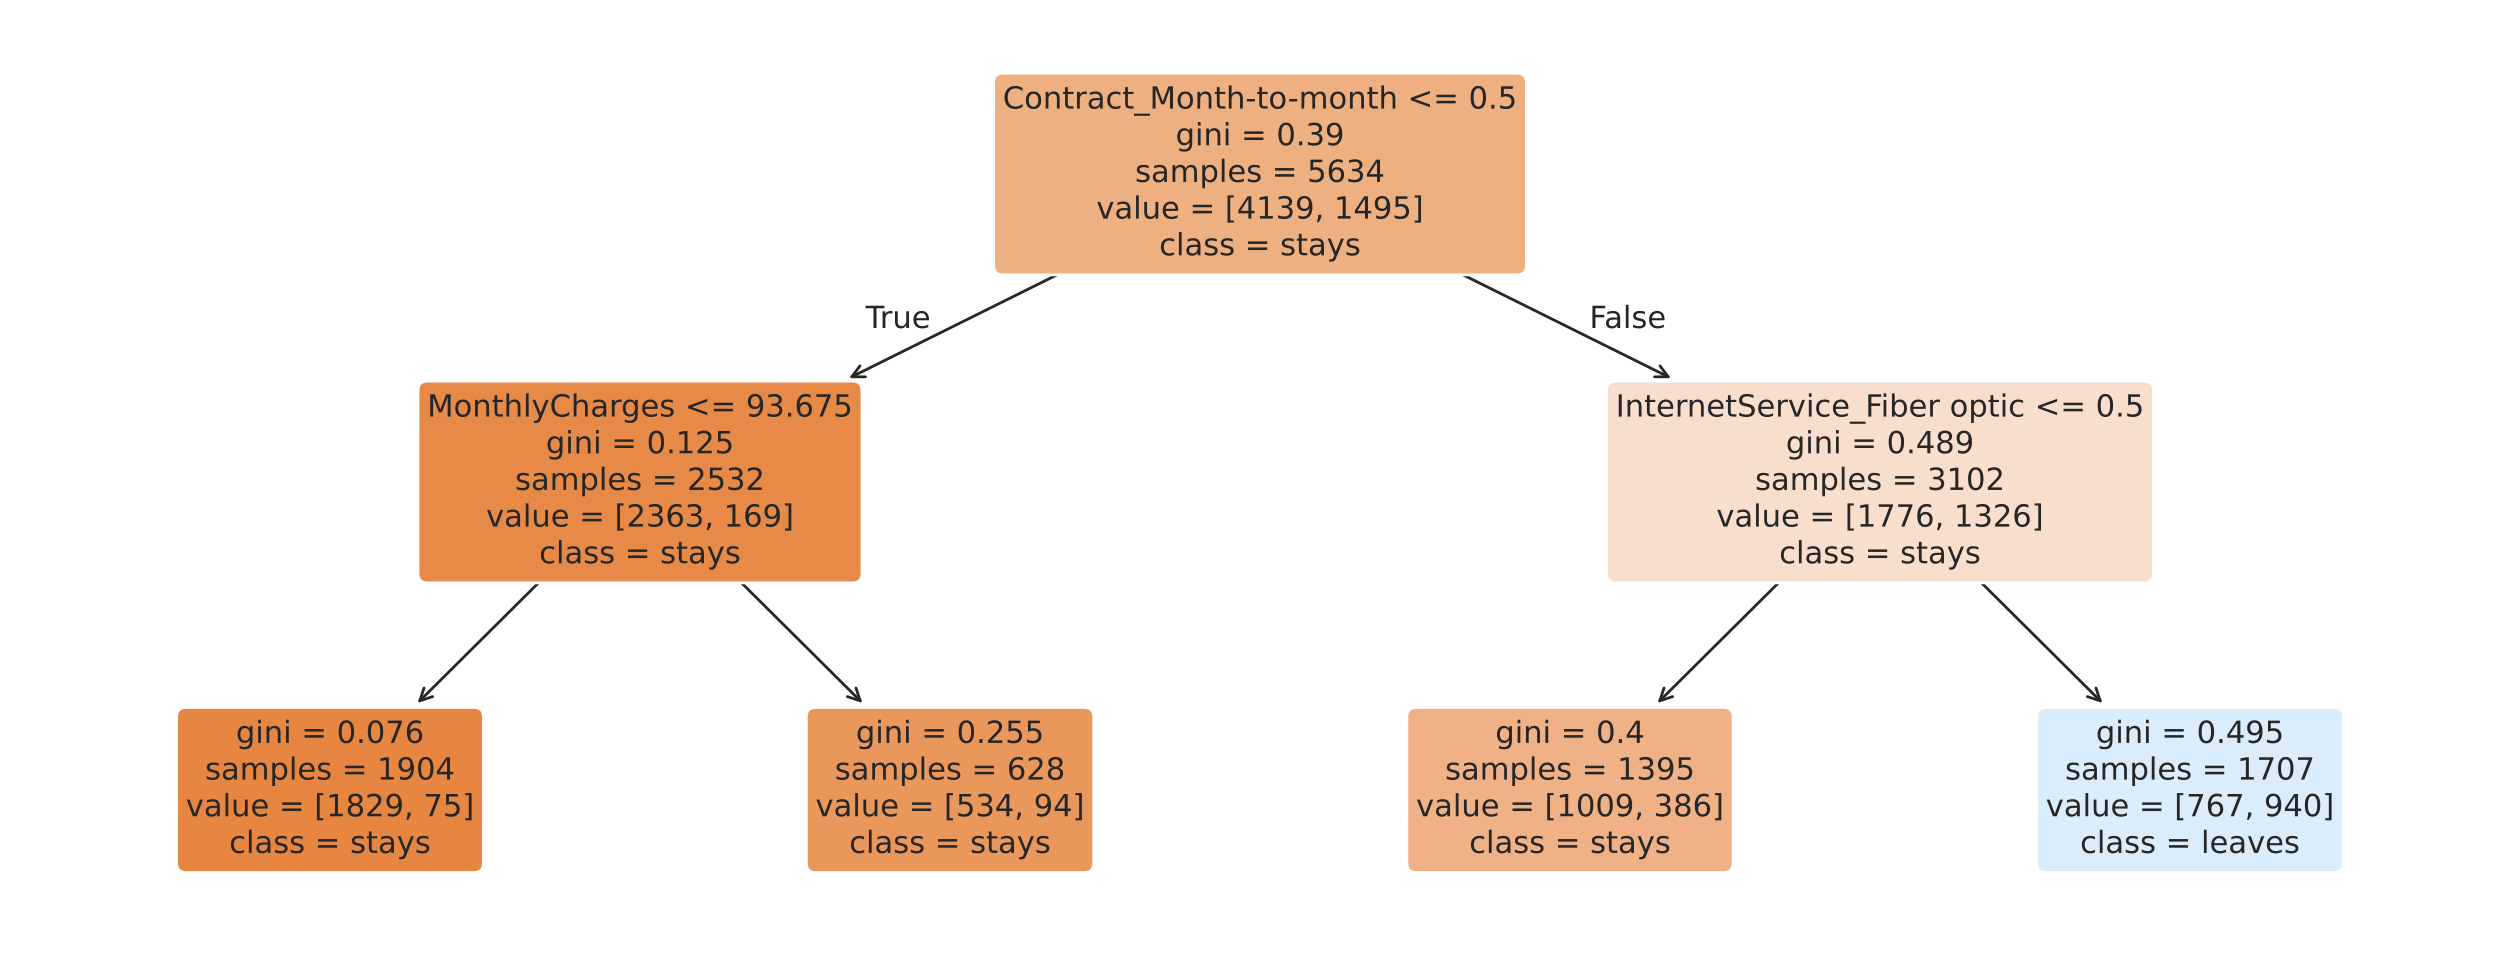

In [3]:
from sklearn.tree import plot_tree
small = tree_model(max_depth=2).fit(X_train, y_train)
names = [n.split('__')[1] for n in small.named_steps['preprocess'].get_feature_names_out()]
plt.figure(figsize=(16, 6))
plot_tree(small.named_steps['model'], feature_names=names, class_names=['stays', 'leaves'],
          filled=True, rounded=True, proportion=False, impurity=True, fontsize=11)
plt.show()

**How to read each box:**
- the **question** (e.g. `Contract_Month-to-month <= 0.5` means *"is the contract NOT month-to-month?"*; left = yes, right = no)
- **gini:** how mixed the box is (0 = all one class, 0.5 = half and half)
- **samples:** customers in the box
- **value:** [stayed, left] counts
- **class:** the majority answer

The tree's first question is the **contract type**: the single question that best separates leavers from stayers. Then it asks about **fiber internet** and the **monthly bill**.

### How did it choose the first question? Gini impurity by hand

In [4]:
def gini(p):            # p = share of leavers in a box
    return 1 - p**2 - (1 - p)**2

m2m = X_train['Contract'] == 'Month-to-month'
p_all, p_m2m, p_other = y_train.mean(), y_train[m2m].mean(), y_train[~m2m].mean()
weighted = (m2m.sum() * gini(p_m2m) + (~m2m).sum() * gini(p_other)) / len(y_train)
print(f'Before the question: churn {p_all:.3f}, gini {gini(p_all):.3f}')
print(f'Month-to-month box:  churn {p_m2m:.3f}, gini {gini(p_m2m):.3f}, customers {m2m.sum()}')
print(f'Other contracts box: churn {p_other:.3f}, gini {gini(p_other):.3f}, customers {(~m2m).sum()}')
print(f'Weighted gini after the question: {weighted:.3f}  -> impurity dropped by {gini(p_all) - weighted:.3f}')

Before the question: churn 0.265, gini 0.390
Month-to-month box:  churn 0.427, gini 0.489, customers 3102
Other contracts box: churn 0.067, gini 0.125, customers 2532
Weighted gini after the question: 0.325  -> impurity dropped by 0.064


The tree tried **every column and every possible cut-point**, computed this drop for each, and picked the biggest. Then it repeats inside each box. This greedy procedure is called **CART**.

### Predicting with the tree: probabilities from leaf proportions

In [5]:
sample = X_test.head(4)
pd.DataFrame({'Contract': sample['Contract'].values, 'InternetService': sample['InternetService'].values,
              'P(leave)': small.predict_proba(sample)[:, 1].round(3), 'prediction': small.predict(sample)})

,Contract,InternetService,P(leave),prediction
0,Two year,Fiber optic,0.150,0
1,Month-to-month,Fiber optic,0.551,1
2,One year,DSL,0.039,0
3,Month-to-month,Fiber optic,0.551,1


Every customer who lands in the same leaf gets the same probability: the share of leavers among the training customers in that leaf.

## Step 16 · Overfitting: let the tree grow with no limits

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

full = tree_model().fit(X_train, y_train)
cv = cross_validate(tree_model(), X_train, y_train, cv=folds, scoring='roc_auc', return_train_score=True)
print('Leaves:', full.named_steps['model'].get_n_leaves(), '| depth:', full.named_steps['model'].get_depth())
print(f"ROC AUC on training data: {cv['train_score'].mean():.3f}")
print(f"ROC AUC on unseen folds:  {cv['test_score'].mean():.3f}")

Leaves: 1102 | depth: 23
ROC AUC on training data: 1.000
ROC AUC on unseen folds:  0.655


A tree with no limits keeps asking questions until every leaf is pure: over a thousand leaves. It is almost **perfect on the data it memorised** and **poor on new customers**. Classic **overfitting**.

### Depth vs score: find the sweet spot

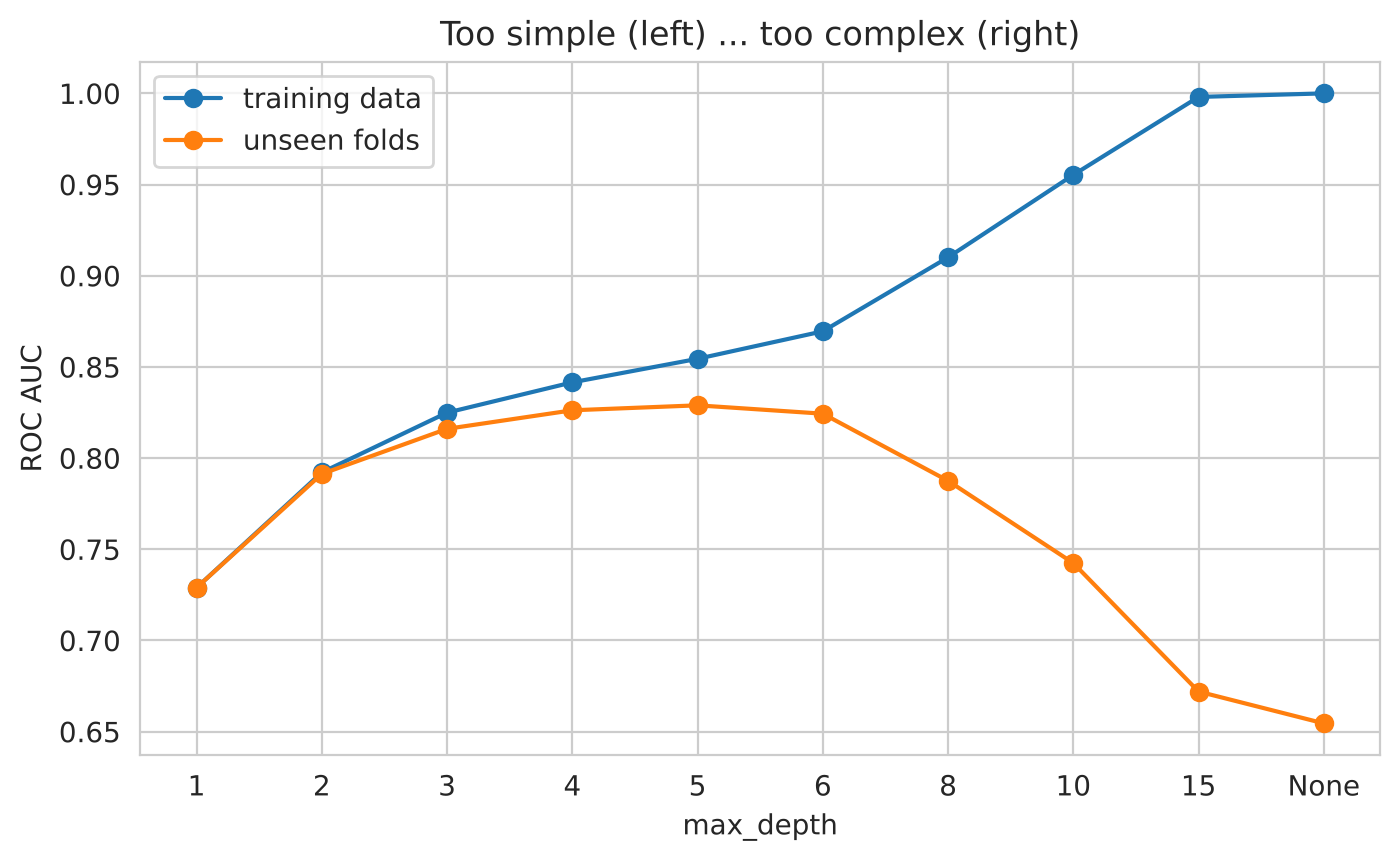

,max_depth,train AUC,validation AUC
0,1,0.729,0.729
1,2,0.792,0.791
2,3,0.825,0.816
3,4,0.842,0.826
4,5,0.854,0.829
5,6,0.870,0.824
6,8,0.910,0.788
7,10,0.955,0.742
8,15,0.998,0.672
9,None,1.000,0.655


In [7]:
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    cv = cross_validate(tree_model(max_depth=d), X_train, y_train, cv=folds, scoring='roc_auc', return_train_score=True)
    rows.append({'max_depth': str(d), 'train AUC': cv['train_score'].mean(), 'validation AUC': cv['test_score'].mean()})
depth_table = pd.DataFrame(rows)
plt.plot(depth_table['max_depth'], depth_table['train AUC'], 'o-', label='training data')
plt.plot(depth_table['max_depth'], depth_table['validation AUC'], 'o-', label='unseen folds')
plt.xlabel('max_depth'); plt.ylabel('ROC AUC'); plt.legend(); plt.title('Too simple (left) ... too complex (right)'); plt.show()
depth_table.round(3)

- **Depth 1–2:** too simple (underfitting): both scores lower.
- **Depth ~5:** the sweet spot for unseen data.
- **Deeper:** training score keeps rising, validation score falls (overfitting).

## Step 18 · Tune two settings together with GridSearchCV
- `max_depth`: the maximum number of questions in a row
- `min_samples_leaf`: every leaf must contain at least this many customers (no "rules" based on 2 people)

In [8]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(tree_model(), {'model__max_depth': [3, 4, 5, 6, 8], 'model__min_samples_leaf': [1, 20, 50, 100]},
                    cv=folds, scoring='roc_auc').fit(X_train, y_train)
print('Best settings:', grid.best_params_)
print('Best CV ROC AUC:', round(grid.best_score_, 4))
best_tree = grid.best_estimator_
print('Leaves in the best tree:', best_tree.named_steps['model'].get_n_leaves())

Best settings: {'model__max_depth': 6, 'model__min_samples_leaf': 100}
Best CV ROC AUC: 0.8329
Leaves in the best tree: 34


Compare: logistic regression in Practical 2 scored about **0.846**. The tuned tree is close, slightly lower, and its rules are readable.

## Step 16 · Which features does the tree use? Two ways to ask
- **Impurity importance** (built in): how much each feature reduced Gini during training. Fast, but biased towards columns with many possible values.
- **Permutation importance:** shuffle one column in the **test** data and measure how much the score drops. Slower but honest.

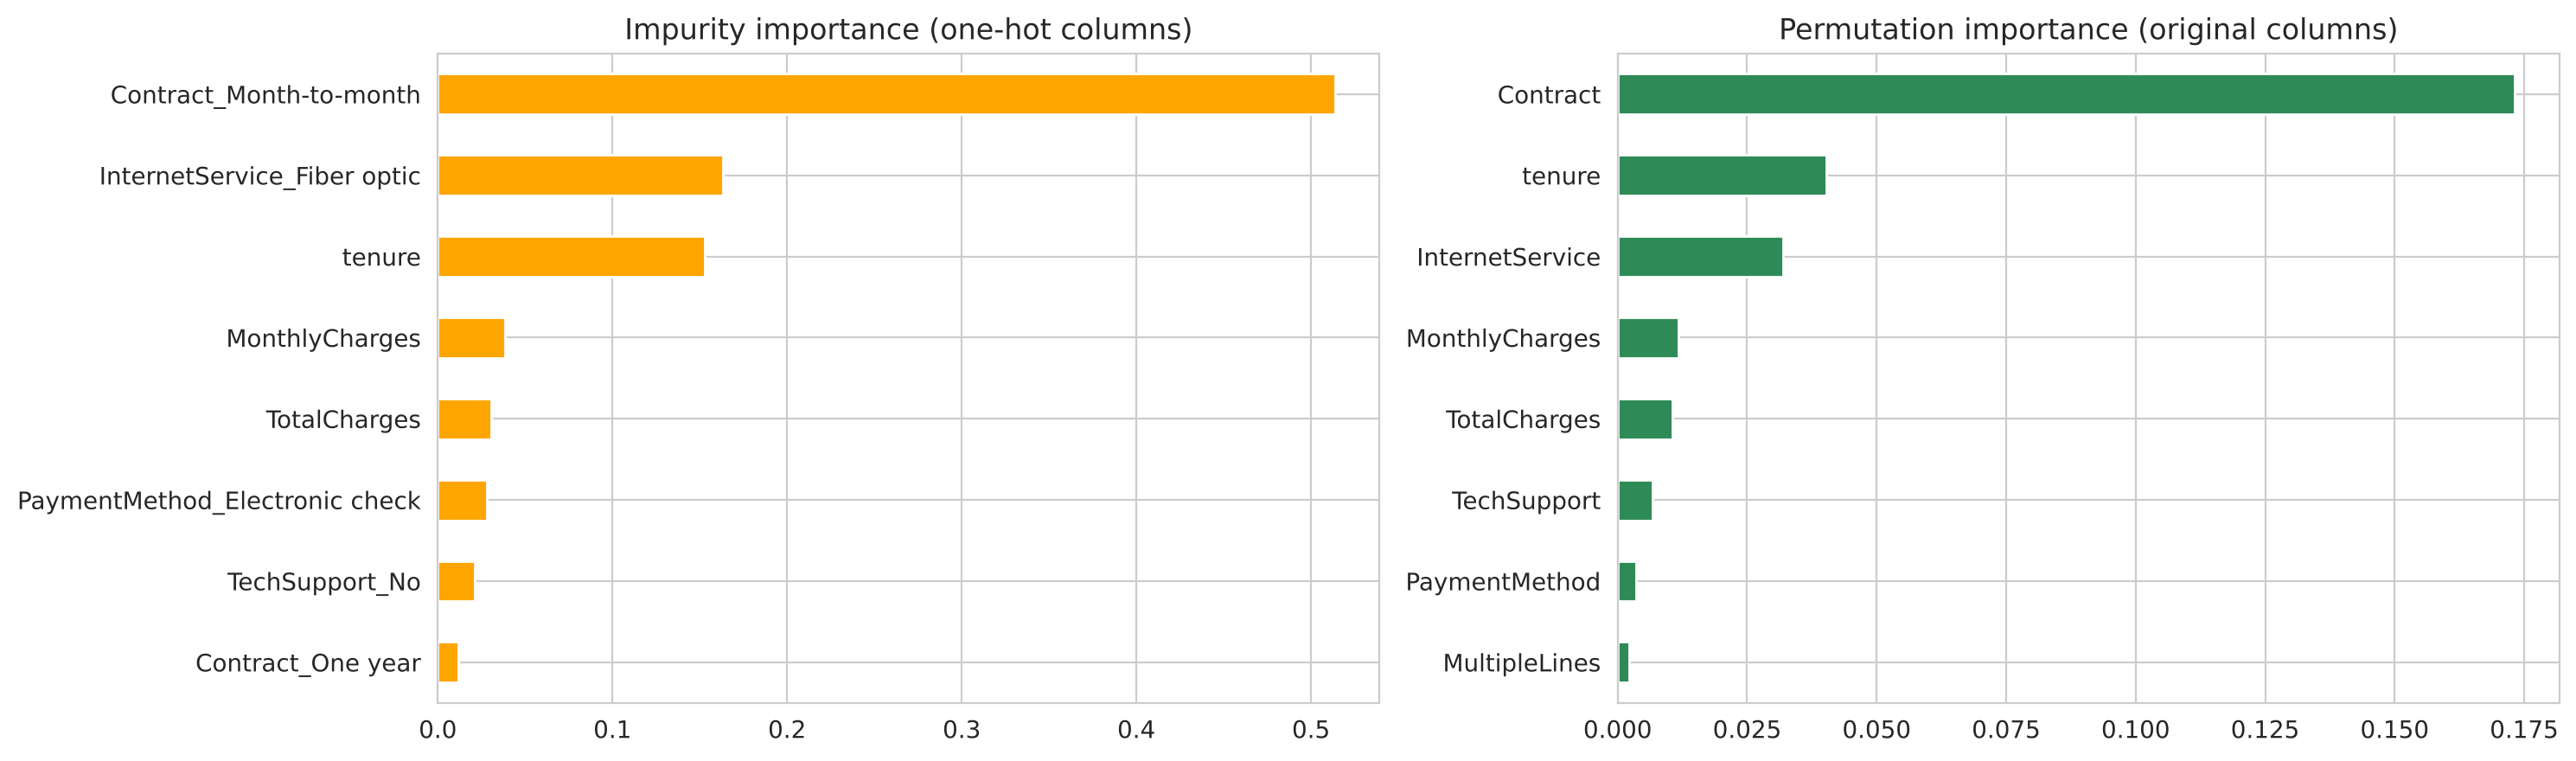

In [9]:
from sklearn.inspection import permutation_importance
names = [n.split('__')[1] for n in best_tree.named_steps['preprocess'].get_feature_names_out()]
impurity = pd.Series(best_tree.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(8)
perm = permutation_importance(best_tree, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=0)
permutation = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(8)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
impurity.sort_values().plot.barh(ax=ax[0], color='orange'); ax[0].set_title('Impurity importance (one-hot columns)')
permutation.sort_values().plot.barh(ax=ax[1], color='seagreen'); ax[1].set_title('Permutation importance (original columns)')
plt.tight_layout(); plt.show()

Both agree: **contract type** dominates, then tenure and internet service.

## Step 19 · Final test, once

In [10]:
from sklearn.metrics import roc_auc_score, classification_report
p = best_tree.predict_proba(X_test)[:, 1]
print('Test ROC AUC:', round(roc_auc_score(y_test, p), 3))
print(classification_report(y_test, (p >= 0.25).astype(int), target_names=['stays', 'leaves'], digits=3))

Test ROC AUC: 0.835
              precision    recall  f1-score   support

       stays      0.904     0.704     0.792      1035
      leaves      0.493     0.794     0.608       374

    accuracy                          0.728      1409
   macro avg      0.699     0.749     0.700      1409
weighted avg      0.795     0.728     0.743      1409



We used the threshold 0.25 chosen in Practical 2 for the same business costs.

## Bonus · A regression tree finds the smoker × BMI pattern by itself
Trees also predict **numbers**: each leaf predicts the **average** of its training rows, and splits are chosen to reduce squared error. Remember Practical 1, where we had to engineer `smoker_obese`? A tree discovers it automatically.

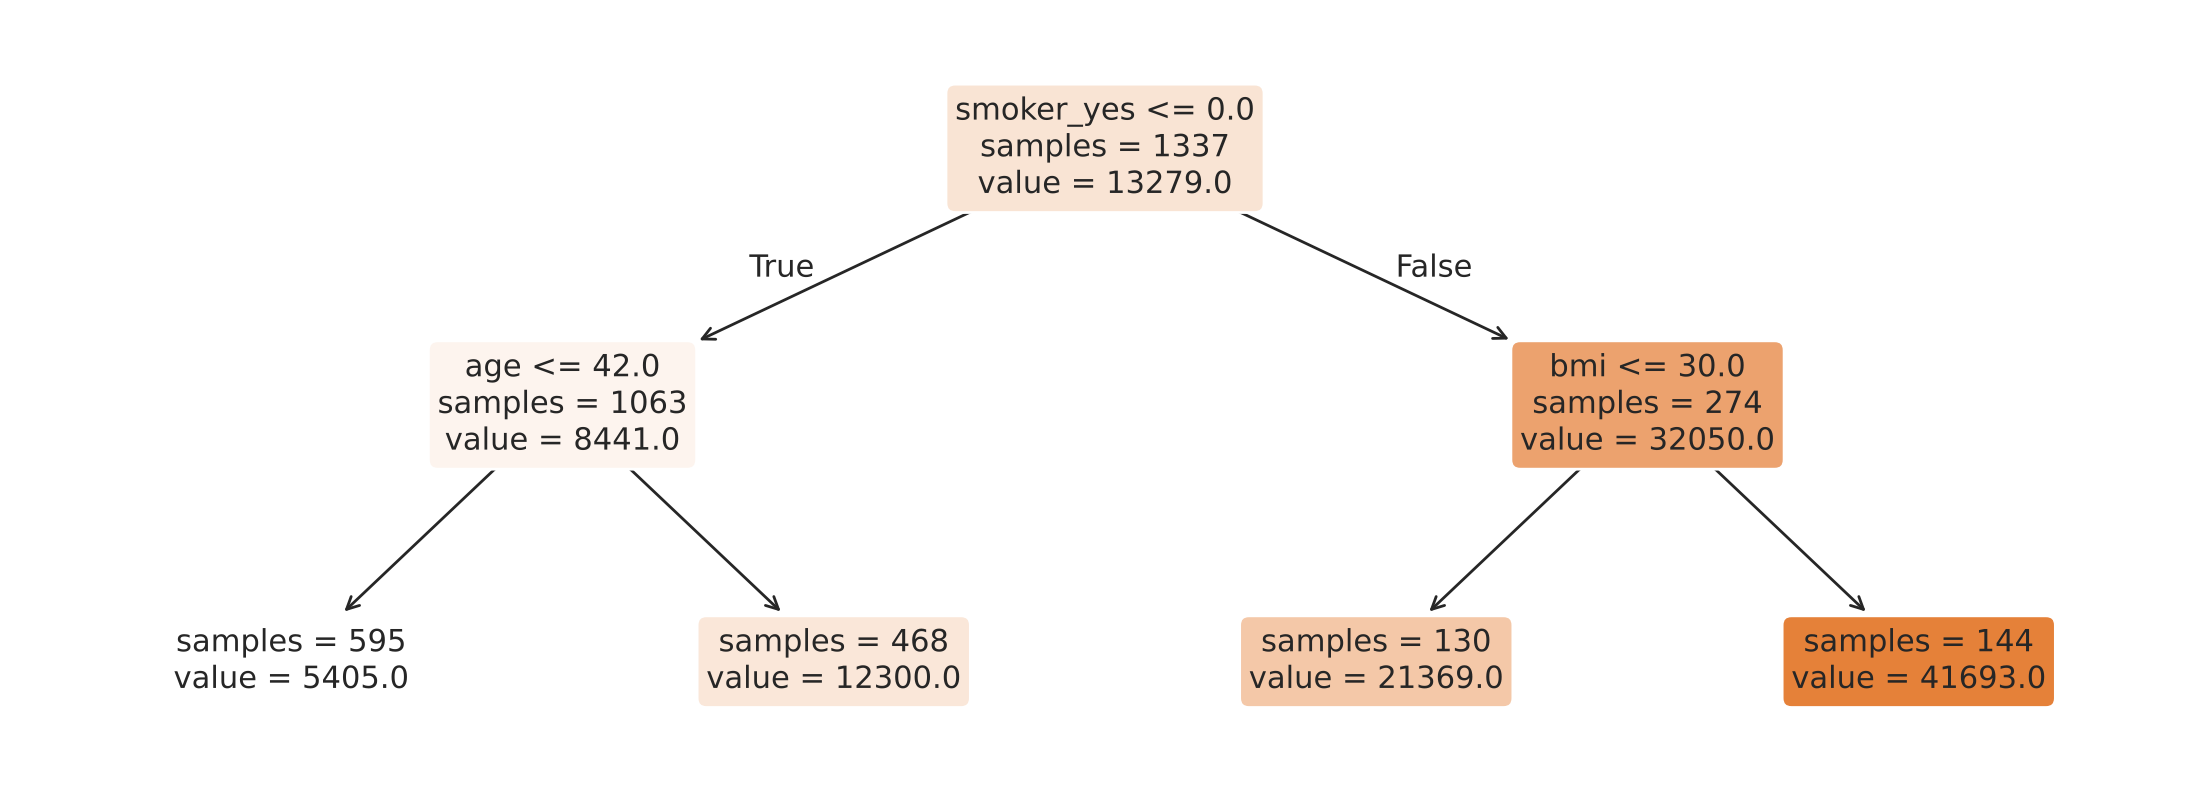

In [11]:
from sklearn.tree import DecisionTreeRegressor
url = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/medical-charges.csv'
if not os.path.exists('medical-charges.csv'):
    urlretrieve(url, 'medical-charges.csv')
med = pd.read_csv('medical-charges.csv').drop_duplicates()
Xm = pd.get_dummies(med.drop(columns='charges'), drop_first=True, dtype=int)
reg_tree = DecisionTreeRegressor(max_depth=2, random_state=0).fit(Xm, med['charges'])
plt.figure(figsize=(14, 5))
plot_tree(reg_tree, feature_names=Xm.columns, filled=True, rounded=True, impurity=False, fontsize=11, precision=0)
plt.show()

First question: **smoker?** For smokers, the next question is **BMI ≤ 30**, exactly the interaction from Practical 1. For non-smokers, it asks about **age**.

## Step 20 · Save

In [12]:
import joblib
joblib.dump(best_tree, 'churn_tree.joblib')
print('Saved. Reload with joblib.load and call predict_proba on new rows.')

Saved. Reload with joblib.load and call predict_proba on new rows.


## Summary
| What | Result |
|---|---|
| A tree asks the question that makes boxes purest (Gini) | first question: contract type |
| No limits → memorises | near-perfect on training data, poor on new data |
| Tune depth + leaf size with cross-validation | close to logistic regression, with readable rules |
| No scaling needed | splits don't care about units |
| Regression trees | found smoker × BMI without feature engineering |

## Exercises
1. Change `criterion` to `'entropy'` in the grid. Does the best score change?
2. Plot the best tree with `plot_tree(..., max_depth=3)`. Write its top three rules in plain English for a manager.
3. Train trees on two different halves of the training data (different `random_state` in a split). Do they ask the same questions below the first one? (This instability is why Part 7 averages many trees.)